# 03 — Padrões frequentes: que combinações de características andam com "obrigada"?

**Para que serve este notebook.** Procurar, sem hipótese prévia, as **combinações de características** que aparecem juntas com frequência nas serventias de MG (atribuições, porte, classe, situação e região) e, principalmente, as que **terminam em "obrigada"** pelo Prov. 227. A pergunta de fundo é: *que tipo de cartório é obrigado a ter a garantia?* Isso ajuda a desenhar o cliente do seguro antes de qualquer modelo.

**Lembrete do mercado.** O Prov. 227 obriga as serventias **providas** (com titular) que **não são Classe 1** (Classe 1 = receita até R$ 300 mil por semestre, Prov. 243) a garantir o passivo trabalhista. Aqui, **"obrigada" = provida e Classe 2 ou 3**, a mesma regra do universo do painel. Este notebook **não muda** nenhum dos 10 números do `docs/ESTADO_ATUAL.md`.

**Termos usados** (explicados com exemplo na seção 3): item, regra de associação, suporte, confiança, lift, Apriori, referência, ganho sobre a referência, melhoria, reamostragem.

**Dados:** banco do pipeline (carga de 19/10/2026: cadastro e arrecadação do CNJ/Justiça Aberta, empregados declarados ao CNJ, regiões do IBGE), cenário **base** com a regra de classe **v2**. Os parâmetros (cortes de porte, suporte e confiança mínimos) estão em `config/analise.yaml`, com a fonte de cada um. Os gráficos também vão em PNG para `docs/qa/analises/`.

In [1]:
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.analise import config, dados, graficos as g, padroes
from src.notebooks import conectar

g.estilo()
cfg = config()["padroes"]
con = conectar()
sv = dados.serventias(con)
trans = padroes.transacoes(sv)
n = len(trans)
p_obrigada = trans["obrigada"].mean()
indeterminadas = sv[sv.classe == "indeterminada"]
print(f"{g.num(len(sv))} serventias ativas; {g.num(len(indeterminadas))} de classe indeterminada ficam fora; "
      f"{g.num(n)} entram na mineração.")
print(f"Obrigadas com classe conhecida: {g.num(trans.obrigada.sum())} ({g.pct(p_obrigada)}). "
      f"Com o peso das indeterminadas providas ({g.num(indeterminadas.peso_universo.sum(), 1)}), o total do painel: "
      f"{g.num(trans.obrigada.sum() + indeterminadas.peso_universo.sum(), 1)}.")

2.525 serventias ativas; 78 de classe indeterminada ficam fora; 2.447 entram na mineração.
Obrigadas com classe conhecida: 1.103 (45,1%). Com o peso das indeterminadas providas (18,3), o total do painel: 1.121,3.


A linha acima liga este notebook ao painel: as **1.103 obrigadas com classe conhecida**, mais o peso das 27 providas de classe indeterminada (18,3), dão as **≈ 1.121 obrigadas** do número oficial nº 3.

**Por que as 78 indeterminadas ficam fora.** Elas não têm receita válida em 2025 (notebook 01), então não sabemos se são Classe 1. No painel, cada uma entra com um peso (a chance de não ser Classe 1); numa regra de associação, cada serventia precisa ter ou não ter o item "obrigada", e um peso fracionário não cabe. Tirar 78 de 2.525 (3,1%) muda pouco as frequências.

## 1. Os itens: como cada serventia vira uma "cesta"

**A pergunta.** Quais características de cada serventia entram na busca de padrões?

**O método.** A mineração de regras de associação nasceu na análise de **cestas de compras** ("quem compra pão costuma comprar manteiga"). Aqui, cada serventia é uma cesta e cada característica é um **item** (verdadeiro ou falso):
- **atribuições** (6): Notas, Registro Civil (RCPN), Registro de Imóveis (RI), Títulos e Documentos (RTD), Pessoas Jurídicas (RCPJ) e Protesto. Uma serventia pode ter várias;
- **porte**, pelo número de empregados CLT declarados ao CNJ, em 4 faixas: 0, 1 a 2, 3 a 9 e 10 ou mais. O corte em 2 é a mediana de MG (notebook 02); o corte em 9 é o teto da microempresa de serviços no critério de porte por pessoas ocupadas do SEBRAE;
- **classe** (1, 2 ou 3, regra v2) e **situação** (provida, vaga ou outras);
- **região intermediária** do IBGE (13 regiões);
- **obrigada** (provida e Classe 2 ou 3).

Exemplo: um cartório de Notas e RCPN, com 2 empregados, Classe 1, provido, na região de Varginha, vira a cesta {Notas, RCPN, porte 1 a 2 CLT, classe 1, situação provida, região Varginha}, sem o item "obrigada".

Por que faixas e não o número exato: o Apriori só trabalha com itens presentes ou ausentes. Usamos o porte pelos **empregados**, e não pela receita, porque a receita já define a classe; assim o porte traz uma informação a mais.

In [2]:
freq_itens = trans.mean().rename("frequencia").to_frame()
freq_itens["serventias"] = trans.sum()
freq_itens["tipo"] = [("atribuição" if i in padroes.ROTULOS_ATRIBUICOES.values() else i.split(" ")[0])
                      for i in freq_itens.index]
ordem = ["atribuição", "porte", "classe", "situação", "região", "obrigada"]
freq_itens = freq_itens.assign(o=freq_itens.tipo.map(ordem.index)).sort_values(["o", "frequencia"],
                                                                               ascending=[True, False], kind="stable")
display(g.tabela(freq_itens.drop(columns="o").reset_index(names="item")[["tipo", "item", "serventias", "frequencia"]],
                 {"serventias": "int", "frequencia": "pct"}))

,tipo,item,serventias,frequencia
0,atribuição,Notas,1.614,"66,0%"
1,atribuição,RCPN,1.386,"56,6%"
2,atribuição,RI,314,"12,8%"
3,atribuição,Protesto,297,"12,1%"
4,atribuição,RCPJ,277,"11,3%"
5,atribuição,RTD,275,"11,2%"
6,porte,porte 1 a 2 CLT,981,"40,1%"
7,porte,porte 3 a 9 CLT,909,"37,1%"
8,porte,porte 0 CLT,285,"11,6%"
9,porte,porte 10+ CLT,269,"11,0%"


**Como ler.** Cada linha é um item e a % de serventias que o têm. As linhas de um mesmo tipo de porte, classe, situação ou região somam 100% (cada serventia tem exatamente um); as atribuições não somam, porque uma serventia pode ter várias.

**O que encontramos.** Notas (66%) e RCPN (57%) são as atribuições mais comuns; RI, RTD, RCPJ e Protesto aparecem em 11% a 13% das serventias cada. Quase 3 em cada 4 serventias têm de 1 a 9 empregados; 11% têm 10 ou mais. **45,1% são obrigadas.**

**Limitações.** As faixas de porte são uma escolha (com fonte, em `config/analise.yaml`); outras faixas mudariam as regras. A situação é a do cadastro do CNJ na coleta (carga de 19/10/2026).

## 2. A referência: quantas são obrigadas em cada atribuição

**A pergunta.** Sabendo só a atribuição de um cartório, qual a chance de ele ser obrigado?

**O método.** Para cada atribuição, contamos as serventias que a têm e a parte delas que é obrigada. Exemplo: se 314 serventias têm RI e 264 delas são obrigadas, a frequência é 264 ÷ 314 = 84%.

Essa frequência simples é a **referência** do notebook (o "chute" do `docs/plano_mineracao.md`, §4): uma regra mais complicada só interessa se disser **mais** do que a atribuição sozinha já diz.

,item,serventias,obrigadas,% obrigadas
2,RI,314,264,"84,1%"
5,Protesto,297,189,"63,6%"
3,RTD,275,165,"60,0%"
4,RCPJ,277,166,"59,9%"
0,Notas,1.614,613,"38,0%"
1,RCPN,1.386,350,"25,3%"


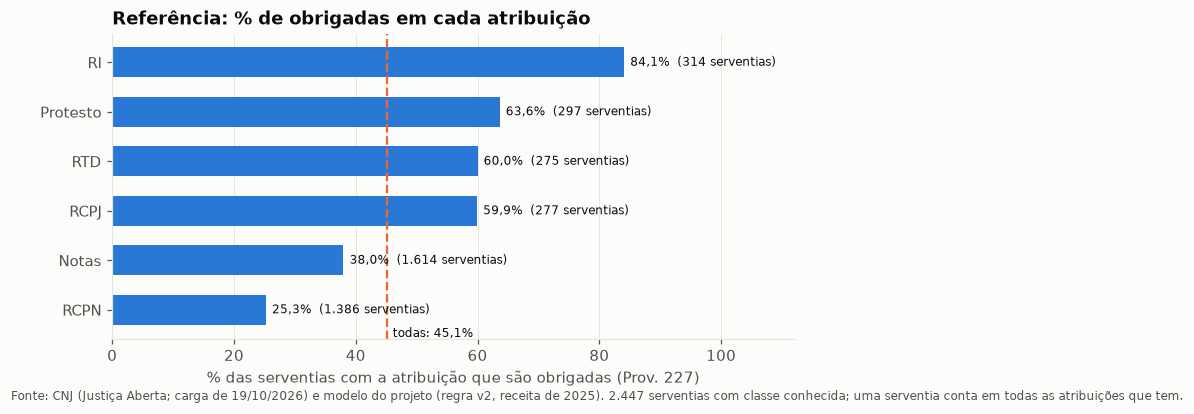

In [3]:
nomes_atrib = list(padroes.ROTULOS_ATRIBUICOES.values())
referencia = padroes.frequencia_por_item(trans, nomes_atrib).sort_values("frequencia", ascending=False)
display(g.tabela(referencia, {"serventias": "int", "com_alvo": "int", "frequencia": "pct"})
        .rename(columns={"com_alvo": "obrigadas", "frequencia": "% obrigadas"}))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(referencia))
ax.barh(y, 100 * referencia.frequencia, color=g.AZUL["medio"], height=0.6)
for i, (f, s) in enumerate(zip(referencia.frequencia, referencia.serventias)):
    ax.text(100 * f + 1, i, f"{g.pct(f)}  ({g.num(s)} serventias)", va="center", fontsize=8, color=g.TEXTO)
ax.axvline(100 * p_obrigada, color=g.CORES[1], linestyle="--", linewidth=1.5)
ax.text(100 * p_obrigada + 1, len(referencia) - 0.45, f"todas: {g.pct(p_obrigada)}", color=g.TEXTO, fontsize=8)
ax.set_yticks(y, referencia["item"])
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("% das serventias com a atribuição que são obrigadas (Prov. 227)")
ax.grid(axis="y", visible=False)
ax.set_title("Referência: % de obrigadas em cada atribuição")
g.nota(fig, f"Fonte: CNJ (Justiça Aberta; carga de 19/10/2026) e modelo do projeto (regra v2, receita de 2025). "
            f"{g.num(n)} serventias com classe conhecida; uma serventia conta em todas as atribuições que tem.")
g.salvar(fig, "03_referencia_obrigadas_por_atribuicao")
plt.show()

**Como ler.** Cada barra é a % de obrigadas entre as serventias com aquela atribuição; a linha tracejada é a % entre todas (45,1%).

**O que encontramos.** O **Registro de Imóveis** é a atribuição mais ligada à obrigação: **84%** das serventias com RI são obrigadas. Protesto, RTD e RCPJ ficam perto de 60%. Notas (38%) e, sobretudo, **RCPN (25%)** ficam **abaixo** da média: o registro civil está em muitos cartórios pequenos, de distrito, quase sempre Classe 1 ou vagos.

**O que significa para o Prov. 227.** Para uma seguradora que só soubesse a atribuição, o RI seria o melhor sinal de cliente obrigado. As regras da seção 4 precisam bater esses números.

**Limitações.** É uma associação, não uma causa: o RI não "causa" a obrigação; ele costuma vir com receita alta.

## 3. Suporte, confiança e lift, com um exemplo

**A pergunta.** Como medir se uma combinação de características "anda junto" com a obrigação?

**O método.** Uma **regra de associação** tem a forma **"se A, então B"**, em que A é um conjunto de itens e B um item. Três medidas dizem se ela vale a pena:
- **suporte** = parte das serventias que têm A **e** B. Diz se a regra é comum ou rara;
- **confiança** = das serventias que têm A, a parte que também tem B. É a "taxa de acerto" da regra;
- **lift** = confiança ÷ frequência de B entre todas. Acima de 1, ter A **aumenta** a chance de B; igual a 1, A não diz nada sobre B.

**Exemplo pequeno (números inventados).** Num grupo de 100 cartórios, 40 são obrigados (frequência de B = 40%). Vinte têm RI, e 16 desses 20 são obrigados. Para a regra "se RI, então obrigada": suporte = 16 ÷ 100 = 16%; confiança = 16 ÷ 20 = 80%; lift = 80% ÷ 40% = 2. Ter RI dobra a chance de ser obrigado.

**O Apriori** (Agrawal e Srikant, 1994) acha todas as combinações com suporte mínimo sem testar todas as possíveis: se um conjunto de itens é raro, qualquer conjunto maior que o contenha também é, e pode ser descartado. Usamos a implementação da biblioteca `mlxtend`. Cortes (em `config/analise.yaml`, `fonte: suposição`): suporte de pelo menos **3%** (≈ 73 serventias), confiança de pelo menos **50%** e no máximo **3 itens no "se"**, para as regras serem lidas numa frase.

Por que regras de associação e não um modelo de classificação: aqui a pergunta é **descrever** combinações frequentes, em linguagem de "se... então...". A classificação (prever um alvo com todas as variáveis) é o notebook 05. Não houve teste de métodos para este notebook (os testes T1 a T7 cobrem os notebooks 05 a 08).

In [4]:
todas = padroes.regras(trans)
exemplo = frozenset(["RI", "porte 3 a 9 CLT"])
tem_a = trans[list(exemplo)].all(axis=1)
tem_ab = tem_a & trans.obrigada
print(f"Regras encontradas com os cortes (todas, com qualquer item no 'então'): {g.num(len(todas))}.")
print(f"Exemplo real — se {{RI, porte 3 a 9 CLT}}, então obrigada: {g.num(tem_a.sum())} serventias têm o 'se'; "
      f"{g.num(tem_ab.sum())} delas são obrigadas.")
print(f"  suporte = {g.num(tem_ab.sum())} ÷ {g.num(n)} = {g.pct(tem_ab.mean())}; "
      f"confiança = {g.num(tem_ab.sum())} ÷ {g.num(tem_a.sum())} = {g.pct(tem_ab.sum() / tem_a.sum())}; "
      f"lift = {g.pct(tem_ab.sum() / tem_a.sum())} ÷ {g.pct(p_obrigada)} = {g.num(tem_ab.sum() / tem_a.sum() / p_obrigada, 2)}.")

Regras encontradas com os cortes (todas, com qualquer item no 'então'): 817.
Exemplo real — se {RI, porte 3 a 9 CLT}, então obrigada: 161 serventias têm o 'se'; 141 delas são obrigadas.
  suporte = 141 ÷ 2.447 = 5,8%; confiança = 141 ÷ 161 = 87,6%; lift = 87,6% ÷ 45,1% = 1,94.


**Como ler.** No exemplo real, o lift perto de 2 quer dizer que uma serventia com RI e de 3 a 9 empregados tem quase o dobro da chance média de ser obrigada.

**Limitações.** O lift compara com a média de todas as serventias, não com a atribuição sozinha; por isso a seção 5 usa também o ganho sobre a referência. Com 817 regras testadas, algumas passam dos cortes por acaso; a reamostragem da seção 5 filtra parte delas.

## 4. Combinações de atribuições

**A pergunta.** Quais atribuições costumam vir juntas no mesmo cartório?

**O método.** As regras da seção 3 em que o "se" e o "então" são só atribuições, ordenadas pelo lift.

In [5]:
atribs = set(nomes_atrib)
so_atrib = todas[todas.antecedentes.apply(lambda a: a <= atribs) & todas.consequente.isin(atribs)].copy()
so_atrib["se"] = so_atrib.antecedentes.apply(lambda a: " + ".join(sorted(a)))
so_atrib["serventias"] = np.rint(so_atrib.suporte * n).astype(int)
display(g.tabela(so_atrib.sort_values(["lift", "suporte", "se", "consequente"], ascending=[False, False, True, True],
                                      kind="stable")
                 [["se", "consequente", "serventias", "suporte", "confianca", "lift"]],
                 {"serventias": "int", "suporte": "pct", "confianca": "pct", "lift": "num2"}))

,se,consequente,serventias,suporte,confianca,lift
189,RCPJ + RI,RTD,150,"6,1%","99,3%","8,84"
186,RCPJ,RTD,275,"11,2%","99,3%","8,83"
449,RTD,RCPJ,275,"11,2%","100,0%","8,83"
387,RI + RTD,RCPJ,150,"6,1%","100,0%","8,83"
212,RCPJ + RTD,RI,150,"6,1%","54,5%","4,25"
450,RTD,RI,150,"6,1%","54,5%","4,25"
185,RCPJ,RI,151,"6,2%","54,5%","4,25"
0,Notas,RCPN,1.175,"48,0%","72,8%","1,29"
278,RCPN,Notas,1.175,"48,0%","84,8%","1,29"


**Como ler.** Cada linha diz: das serventias com o "se", que % também tem o "consequente".

**O que encontramos.**
- **RTD e RCPJ andam sempre juntos**: toda serventia com RTD tem RCPJ, e 99% das com RCPJ têm RTD (lift ≈ 8,8). Na prática, em MG, são uma atribuição só (o "registro de títulos e documentos e civil das pessoas jurídicas").
- Pouco mais da metade das serventias com RTD/RCPJ também tem **RI** (lift ≈ 4,3): é o cartório de registro "completo" das cidades médias.
- **Notas e RCPN** juntos é a combinação mais comum (48% das serventias), típica do cartório de distrito.

**O que significa para o Prov. 227.** Contar RTD e RCPJ como duas variáveis separadas não acrescenta informação; o notebook 04 (grupos) e os modelos do 05 devem lembrar disso ao ler os pesos.

**Limitações.** Essas regras descrevem como as atribuições estão distribuídas entre os cartórios de MG; não valem automaticamente para outros estados.

## 5. As regras que terminam em "obrigada"

**A pergunta.** Que combinações de atribuição, porte e região apontam para um cartório obrigado, **além do que a atribuição sozinha já diz**?

**O método.** Partimos das regras da seção 3 com "então obrigada" e aplicamos quatro filtros, nesta ordem:
1. **Fora as regras de definição.** "Obrigada" é, por definição, "provida e Classe 2 ou 3". Uma regra como "se classe 3 e provida, então obrigada" acerta 100% sem ensinar nada. Por isso, as regras com algum item de **classe** ou de **situação** no "se" saem (é o equivalente, aqui, ao **vazamento** do `plano_mineracao.md`, §4: uma variável que entrega a resposta).
2. **Ganho sobre a referência > 1.** A referência de cada regra é a maior % de obrigadas entre as atribuições do "se" (seção 2); se não houver atribuição, é a % geral (45,1%). Ganho = confiança ÷ referência. Exemplo: "se RI e 3 a 9 CLT" acerta 88%, contra 84% do RI sozinho: ganho = 1,04.
3. **Melhoria mínima** (Bayardo, Agrawal e Gunopulos, 2000). Cada item a mais no "se" precisa subir a confiança em pelo menos **2 pontos percentuais** em relação a todas as regras com parte dos itens. Isso tira regras "enfeitadas", como "se RI e Notas e 3 a 9 CLT" quando o "Notas" não muda nada.
4. **Estabilidade.** Refazemos tudo em **2 reamostragens de 80%** das serventias (sorteadas sem reposição, semente fixa de `config/analise.yaml`) e ficam só as regras que aparecem nas duas. Uma regra que some quando tiramos 20% dos cartórios era sorte da amostra.

As regras que sobram são ordenadas pelo **lift**.

In [6]:
definicao = todas[(todas.consequente == "obrigada") & ~todas.antecedentes.apply(padroes.sem_definidores)]
candidatas = padroes.regras_alvo(trans, todas)
vezes = padroes.estabilidade(trans)
principais = padroes.tabela_regras(candidatas, trans, vezes)
candidatas["reamostragens"] = candidatas.antecedentes.map(vezes).fillna(0).astype(int)
print(f"Regras com 'então obrigada': {g.num((todas.consequente == 'obrigada').sum())}; "
      f"de definição (classe ou situação no 'se'): {g.num(len(definicao))}, com confiança mediana de "
      f"{g.pct(definicao.confianca.median())}.")
print(f"Depois do ganho e da melhoria: {g.num(len(candidatas))}; presentes nas {cfg['reamostragens']} reamostragens: "
      f"{g.num((candidatas.reamostragens >= cfg['reamostragens']).sum())}.")
candidatas["se"] = candidatas.antecedentes.apply(lambda a: " + ".join(sorted(a)))
display(g.tabela(candidatas[["se", "suporte", "confianca", "lift", "referencia", "ganho", "melhoria", "reamostragens"]],
                 {"suporte": "pct", "confianca": "pct", "lift": "num2", "referencia": "pct", "ganho": "num2",
                  "melhoria": "pct"}))

Regras com 'então obrigada': 124; de definição (classe ou situação no 'se'): 91, com confiança mediana de 88,6%.
Depois do ganho e da melhoria: 14; presentes nas 2 reamostragens: 11.


,se,suporte,confianca,lift,referencia,ganho,melhoria,reamostragens
0,RI + porte 3 a 9 CLT,"5,8%","87,6%","1,94","84,1%","1,04","3,5%",2
1,Notas + porte 10+ CLT,"3,1%","85,4%","1,89","38,0%","2,25","3,2%",1
2,porte 3 a 9 CLT + região Pouso Alegre,"3,4%","83,7%","1,86","45,1%","1,86","10,0%",2
3,porte 10+ CLT,"9,0%","82,2%","1,82","45,1%","1,82","37,1%",2
4,RCPJ + porte 3 a 9 CLT,"4,4%","79,4%","1,76","59,9%","1,33","5,7%",2
5,RTD + porte 3 a 9 CLT,"4,4%","79,3%","1,76","60,0%","1,32","5,6%",2
6,Protesto + porte 3 a 9 CLT,"4,7%","78,1%","1,73","63,6%","1,23","4,4%",2
7,porte 3 a 9 CLT,"27,4%","73,7%","1,64","45,1%","1,64","28,6%",2
8,Notas + Protesto,"3,1%","73,5%","1,63","63,6%","1,16","9,9%",0
9,região Divinópolis,"4,5%","61,1%","1,36","45,1%","1,36","16,0%",2


**Como ler.** Cada linha é uma regra "se ..., então obrigada" que passou pelos filtros 1 a 3; a última coluna diz em quantas das 2 reamostragens ela reaparece. As que aparecem nas 2 são as **regras estáveis**; as 10 com maior lift são as **principais** (tabela e gráfico a seguir).

,posicao,se,serventias_com_se,serventias_com_se_e_entao,confianca,lift,referencia,ganho_sobre_referencia
0,1,RI + porte 3 a 9 CLT,161,141,"87,6%","1,94","84,1%","1,04"
1,2,porte 3 a 9 CLT + região Pouso Alegre,98,82,"83,7%","1,86","45,1%","1,86"
2,3,porte 10+ CLT,269,221,"82,2%","1,82","45,1%","1,82"
3,4,RCPJ + porte 3 a 9 CLT,136,108,"79,4%","1,76","59,9%","1,33"
4,5,RTD + porte 3 a 9 CLT,135,107,"79,3%","1,76","60,0%","1,32"
5,6,Protesto + porte 3 a 9 CLT,146,114,"78,1%","1,73","63,6%","1,23"
6,7,porte 3 a 9 CLT,909,670,"73,7%","1,64","45,1%","1,64"
7,8,região Divinópolis,180,110,"61,1%","1,36","45,1%","1,36"
8,9,região Pouso Alegre,209,122,"58,4%","1,30","45,1%","1,30"
9,10,região Belo Horizonte,317,174,"54,9%","1,22","45,1%","1,22"


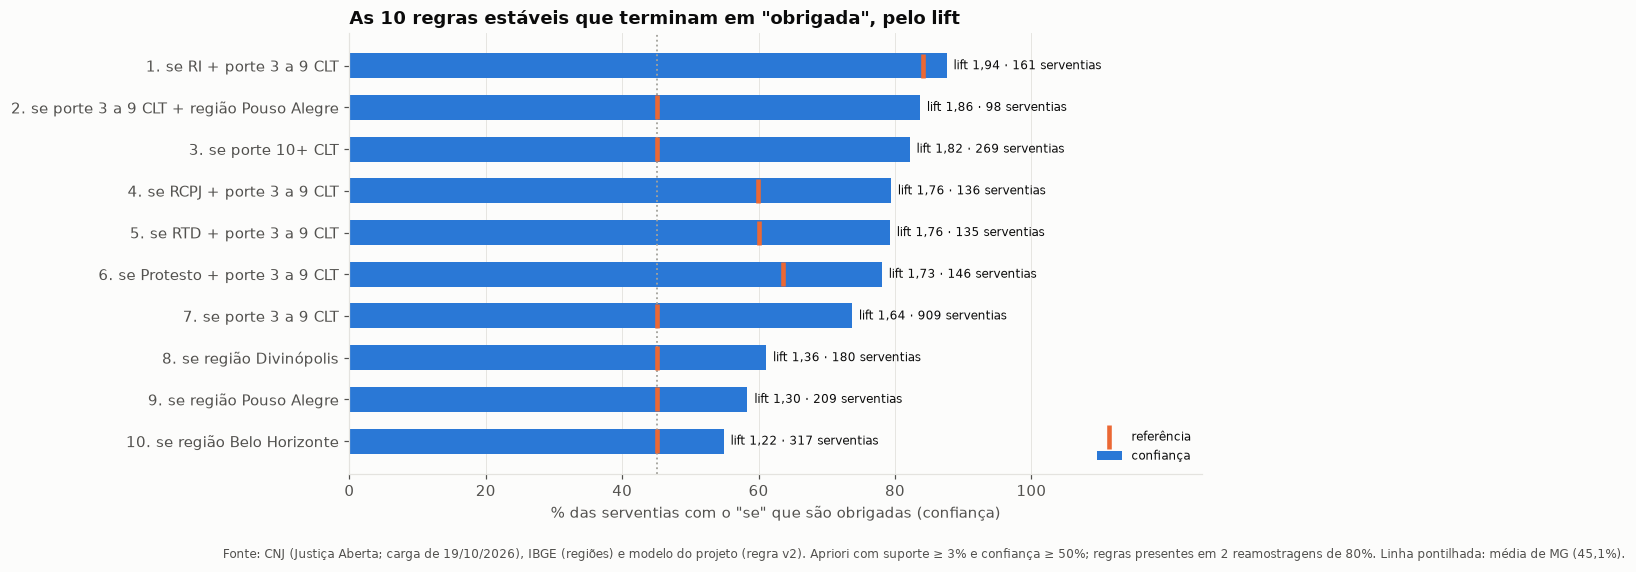

In [7]:
mostrar = principais.copy()
display(g.tabela(mostrar[["posicao", "se", "serventias_com_se", "serventias_com_se_e_entao", "confianca", "lift",
                          "referencia", "ganho_sobre_referencia"]],
                 {"serventias_com_se": "int", "serventias_com_se_e_entao": "int", "confianca": "pct", "lift": "num2",
                  "referencia": "pct", "ganho_sobre_referencia": "num2"}))

fig, ax = plt.subplots(figsize=(10, 5.2))
y = np.arange(len(mostrar))
ax.barh(y, 100 * mostrar.confianca, color=g.AZUL["medio"], height=0.6, label="confiança")
ax.scatter(100 * mostrar.referencia, y, marker="|", s=260, linewidths=3, color=g.CORES[1], zorder=3,
           label="referência")
for i, r in mostrar.iterrows():
    ax.text(100 * r.confianca + 1, i, f"lift {g.num(r.lift, 2)} · {g.num(r.serventias_com_se)} serventias",
            va="center", fontsize=8, color=g.TEXTO)
ax.axvline(100 * p_obrigada, color=g.CINZA, linestyle=":", linewidth=1.2)
ax.set_yticks(y, [f"{p}. se {s}" for p, s in zip(mostrar.posicao, mostrar.se)])
ax.invert_yaxis()
ax.set_xlim(0, 125)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("% das serventias com o \"se\" que são obrigadas (confiança)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("As 10 regras estáveis que terminam em \"obrigada\", pelo lift")
g.nota(fig, f"Fonte: CNJ (Justiça Aberta; carga de 19/10/2026), IBGE (regiões) e modelo do projeto (regra v2). Apriori com "
            f"suporte ≥ {g.pct(cfg['suporte_min'], 0)} e confiança ≥ {g.pct(cfg['confianca_min'], 0)}; regras presentes "
            f"em {cfg['reamostragens']} reamostragens de {g.pct(cfg['fracao'], 0)}. Linha pontilhada: média de MG ({g.pct(p_obrigada)}).")
g.salvar(fig, "03_regras_obrigada_principais")
plt.show()

**Como ler.** A barra azul é a confiança da regra (a % de obrigadas entre as serventias com o "se"); o traço laranja é a referência. Quanto mais a barra passa do traço, mais a regra diz além da atribuição sozinha.

**O que encontramos.**
- **O porte pelos empregados é o padrão mais forte.** Ter **10 ou mais CLT** sozinho dá 82% de obrigadas (lift 1,8) e **3 a 9 CLT**, 74% (lift 1,6). Somar uma atribuição de registro ao porte médio sobe a confiança: **RI com 3 a 9 CLT, 88%** (o maior lift, ≈ 1,9); RCPJ, RTD ou Protesto com 3 a 9 CLT, de 78% a 79%.
- **Algumas regiões têm mais obrigadas que a média**, mesmo sem saber a atribuição: Divinópolis (61%), Pouso Alegre (58%) e Belo Horizonte (55%), entre as 10 principais; Varginha (54%) também é estável, mas fica em 11º pelo lift. Em Pouso Alegre, com 3 a 9 CLT, chega a 84%.
- As regras que **não** passaram dão pistas também: "Notas com 10+ CLT" tem ganho alto, mas apareceu em só 1 das 2 reamostragens; "Notas e Protesto" e "Notas na região de Varginha" sumiram nas duas. Ficam de fora por não serem estáveis.

**O que significa para o Prov. 227.** O cliente do seguro é, antes de tudo, o cartório **com equipe**: 3 ou mais empregados já põe a chance de ser obrigado acima de 70%, e isso faz sentido, porque o passivo que a garantia cobre cresce com o número de empregados. As atribuições de registro (RI, RTD/RCPJ, Protesto) reforçam o sinal. Para uma seguradora, o número de empregados declarado ao CNJ, que é público, é um bom primeiro filtro de prospecção.

**Limitações.**
- O porte pelos empregados e a classe pela receita andam juntos (Spearman 0,83 entre receita e CLT, notebook 02): parte do que a regra do porte "acerta" é a receita por trás.
- As regras descrevem MG em 2025; não são previsão de quem será obrigado no futuro (isso é o notebook 05b).
- Os cortes de suporte, confiança e melhoria são suposições: cortes mais baixos dariam mais regras, menos estáveis.

## 6. Desenho da tabela `gold.analise_regras`

**O que é.** A tabela que o painel vai ler (gerada pelo pipeline na Etapa 2, pela função `padroes.tabela_regras`, que tem teste). Uma linha por regra principal:

| Coluna | Tipo | O que é |
|---|---|---|
| `posicao` | inteiro | ordem pelo lift (1 = maior) |
| `se` | texto | itens do "se", separados por " + " |
| `entao` | texto | o item do "então" (aqui, sempre `obrigada`) |
| `n_itens_se` | inteiro | quantos itens no "se" |
| `serventias_com_se` | inteiro | serventias com todos os itens do "se" |
| `serventias_com_se_e_entao` | inteiro | dessas, quantas são obrigadas |
| `suporte`, `confianca`, `lift` | decimal | as medidas da seção 3 (de 0 a 1; o lift sem limite) |
| `referencia` | decimal | a % de obrigadas da melhor atribuição do "se" (ou a média de MG) |
| `ganho_sobre_referencia` | decimal | confiança ÷ referência |
| `melhoria` | decimal | quanto a regra sobe a confiança sobre as regras com parte dos itens |
| `reamostragens_com_a_regra` | inteiro | em quantas reamostragens de 80% a regra reapareceu |

No pipeline, cada linha leva também a data da carga, o nível e a regra de classe, como as outras tabelas do gold.

In [8]:
display(principais)

,posicao,se,entao,n_itens_se,serventias_com_se,serventias_com_se_e_entao,suporte,confianca,lift,referencia,ganho_sobre_referencia,melhoria,reamostragens_com_a_regra
0,1,RI + porte 3 a 9 CLT,obrigada,2,161,141,0.057622,0.875776,1.942906,0.840764,1.041643,0.035012,2
1,2,porte 3 a 9 CLT + região Pouso Alegre,obrigada,2,98,82,0.033510,0.836735,1.856292,0.450756,1.856292,0.099661,2
2,3,porte 10+ CLT,obrigada,1,269,221,0.090315,0.821561,1.822630,0.450756,1.822630,0.370805,2
3,4,RCPJ + porte 3 a 9 CLT,obrigada,2,136,108,0.044136,0.794118,1.761746,0.599278,1.325124,0.057044,2
4,5,RTD + porte 3 a 9 CLT,obrigada,2,135,107,0.043727,0.792593,1.758363,0.600000,1.320988,0.055519,2
5,6,Protesto + porte 3 a 9 CLT,obrigada,2,146,114,0.046588,0.780822,1.732250,0.636364,1.227006,0.043748,2
6,7,porte 3 a 9 CLT,obrigada,1,909,670,0.273805,0.737074,1.635194,0.450756,1.635194,0.286318,2
7,8,região Divinópolis,obrigada,1,180,110,0.044953,0.611111,1.355747,0.450756,1.355747,0.160355,2
8,9,região Pouso Alegre,obrigada,1,209,122,0.049857,0.583732,1.295007,0.450756,1.295007,0.132976,2
9,10,região Belo Horizonte,obrigada,1,317,174,0.071107,0.548896,1.217723,0.450756,1.217723,0.098140,2


## 7. Conclusões

1. **A atribuição sozinha já separa bastante:** 84% das serventias com RI são obrigadas, contra 25% das com RCPN (média de MG: 45,1%).
2. **O porte pelos empregados é o padrão mais forte e estável:** com 3 a 9 CLT, 74% são obrigadas; com 10 ou mais, 82%. Junto com RI, 88%.
3. **RTD e RCPJ são, na prática, a mesma atribuição em MG**, e metade delas vem com RI.
4. **Algumas regiões (Divinópolis, Pouso Alegre, BH, Varginha) têm mais obrigadas que a média**, o que o notebook 04 e o mapa do painel podem mostrar.
5. As regras são descrição de 2025, não previsão; o modelo de quem passa a ser obrigado está no notebook 05b.

> **Atualização (2026-10-28, D-046): premissas v3.** As saídas deste notebook são da carga com as premissas v2. Desde a D-046, a chance de déficit e a parte descoberta vêm da capacidade de pagar do titular (M1, notebook 10), e não mais de suposição. Os números 1 a 5 e o 10 não mudaram; o déficit, a IS e o prêmio caíram 7,5% (prêmio de R$ 368,7 mil para R$ 341,1 mil), e a contagem "com déficit" foi de ≈ 486 para ≈ 148. O que este notebook diz sobre dados, classes, passivo e universo continua valendo; os valores de déficit e prêmio atuais estão no `notebooks/09_conclusoes_lacunas.ipynb`. A D-046 também manteve o valor declarado nos semestres com salto grosseiro (com aviso no pipeline e sensibilidade "sem os saltos") e deixou os dados como os de 17 e 18/10.